# ДЗ 3: бейзлайны и основная модель валидации БТ

Оценка конфигураций из этапа 2 дизайн-документа (план - раздел 2.3, результаты - раздел 2.4) на задаче A: статус каждого из 17 проверяемых по тексту пунктов чеклиста и скор полноты документа.

**Постановка эксперимента**

| | |
| --- | --- |
| Корпус | 5 согласованных БТ после нормализации HTML и 20 испорченных копий, по 4 на БТ: удаление раздела, очистка содержимого раздела, две замены раздела на заглушку `[уточнить]` |
| Разметка | 85 меток оригиналов с цитатами-доказательствами; разметка автора работы в один проход, экспертом не проверена. Зафиксирована до первого запуска моделей (SHA-256 файла - в `metrics.json`). Метки копий выводятся автоматически: пункт, все цитаты которого удалены, становится `missing` или `partial_placeholder` |
| Модель | gemma3:12b (Q4_K_M) локально через Ollama, temperature 0.1, seed = номер запуска; продуктовая модель не вызывалась |
| Подбор | промпт MVP подбирался на doc_02 и doc_04 (срез `original_dev`); doc_01, doc_03, doc_05 в подборе не участвовали (`original_heldout`). Обучаемый B2 - кросс-валидация по исходному БТ: оригинал и его копии целиком в одном фолде |
| Срезы | `original` - 77 оценимых пунктов оригиналов (8 пунктов `not_applicable` по разметке исключены); `affected` - 37 пунктов копий, изменённых порчей; `eval` - оба вместе. Нетронутые пункты копий в метрики качества не входят: по ним проверяется, не меняет ли модель ответ без причины |
| Интервалы | бутстреп по 5 исходным БТ, ориентировочные: при 5 группах различных выборок мало |

`not_applicable` на пункте, который по разметке применим, считается ошибкой: в QWK он приравнивается к `missing`, его доля показана отдельно.

**Конфигурации**

| Имя | Роль | Что это |
| --- | --- | --- |
| B0.5 | бейзлайн | самый частый статус пункта на других исходных БТ |
| B1 | бейзлайн | правила по заголовкам разделов |
| B2 | бейзлайн | сходство пункта с фрагментами документа (bge-m3) и логистическая регрессия |
| B3 | бейзлайн | системный промпт продукта как есть, на нормализованном тексте, 1 запуск |
| B3 на HTML | абляция | промпт продукта на сыром HTML, как в продукте; только 5 оригиналов |
| B3-lite | бейзлайн | короткий промпт без правил, цитат и примера, та же JSON-схема |
| MVP | основная модель | правила и определения статусов, цитата-доказательство, JSON-схема, синтетический пример |
| MVP + проверка цитат | абляция | MVP, где `completed` и `partial` без найденной в тексте цитаты понижаются до `missing` |

Тексты документов, цитаты и ответы модели лежат локально в `data/` и в репозиторий не попадают; здесь только агрегаты.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from reqassist.evaluate import build_gold, evaluate, load_llm_runs, save_report
from reqassist.experiment import Paths, load_corpus, raw_html
from reqassist.metrics import completeness_score

ROOT = Path("..").resolve()
paths = Paths(
    Path(os.environ.get("REQASSIST_DIR", ROOT.parent / "ReqAssist")).resolve(), ROOT / "data"
)
FIG = ROOT / "reports/figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

report = evaluate(paths)
save_report(report, ROOT / "reports/hw3/metrics.json")
docs = load_corpus(paths)
gold = build_gold(paths, docs)
manifest = {
    m["doc_id"]: m
    for m in json.loads((paths.data / "corpus/manifest.json").read_text(encoding="utf-8"))
}
originals = [d for d in docs if d.doc_id == d.source_id]


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Предобработка и разметка

Нормализация: контент страницы (`#main-content`) в markdown с заголовками, списками и таблицами (объединённые ячейки разворачиваются), изображения заменяются отметкой. Вход модели сокращается в несколько раз:

In [2]:
prep = pd.DataFrame(
    [
        {
            "документ": d.doc_id,
            "символов HTML": len(raw_html(paths, d.doc_id)),
            "символов после нормализации": len(d.text),
            "разделов": len(d.sections),
        }
        for d in originals
    ]
).set_index("документ")
prep["сокращение, раз"] = (prep["символов HTML"] / prep["символов после нормализации"]).round(1)
prep

,символов HTML,символов после нормализации,разделов,"сокращение, раз"
документ,,,,
doc_01,61221,22467,12,2.7
doc_02,21922,8262,8,2.7
doc_03,9590,4325,5,2.2
doc_04,6553,2495,7,2.6
doc_05,45722,15883,13,2.9


In [3]:
pd.DataFrame(report["gold"]).fillna(0).astype(int).T

,partial,completed,missing,not_applicable,partial_placeholder
original,26,13,38,8,0
affected,2,0,23,0,12


Разметка оригиналов почти не содержит `partial_placeholder`: в согласованных БТ заглушек нет. Этот класс появляется только в испорченных копиях, где заглушка - известная строка, поэтому его обнаружение на копиях - простой случай.

## 2. Сводная таблица

In [4]:
order = ["B0.5", "B1", "B2", "B3", "B3 на HTML", "B3-lite", "MVP", "MVP + проверка цитат"]
rows = []
for name in order:
    if name not in report["methods"]:
        continue
    e = report["methods"][name]
    o, h, a, ev = e["original"], e["original_heldout"], e["affected"], e["eval"]
    rows.append(
        {
            "конфигурация": name,
            "запусков": e["runs"],
            "QWK, оригиналы": o.get("qwk"),
            "QWK, 3 БТ вне подбора": h.get("qwk"),
            "QWK, eval": ev.get("qwk"),
            "macro-F1, eval": ev.get("macro_f1"),
            "recall missing, оригиналы": o.get("missing_recall"),
            "recall missing, 3 БТ вне подбора": h.get("missing_recall"),
            "recall missing, eval": ev.get("missing_recall"),
            "ложные completed, eval": ev.get("false_completed"),
            "macro-F1, оригиналы": o.get("macro_f1"),
            "n/a на применимых, оригиналы": o.get("na_on_applicable"),
            "QWK, порча": a.get("qwk"),
            "recall missing, порча": a.get("missing_recall"),
            "ложные completed, порча": a.get("false_completed"),
            "MAE скора": e["score_mae"],
            "размах скора, макс": e["score_range_max"],
            "совпадение запусков": e.get("run_agreement"),
            "согласованность копий": e["unaffected_consistency"],
        }
    )
summary = pd.DataFrame(rows).set_index("конфигурация")
summary.round(2).T

конфигурация,B0.5,B1,B2,B3,B3 на HTML,B3-lite,MVP,MVP + проверка цитат
запусков,1.00,1.00,1.00,1.00,1.00,3.00,3.00,3.00
"QWK, оригиналы",0.21,0.25,0.25,0.15,0.01,0.58,0.46,0.42
"QWK, 3 БТ вне подбора",0.24,0.22,0.24,0.15,0.06,0.55,0.44,0.38
"QWK, eval",0.13,0.26,0.21,0.15,0.01,0.39,0.39,0.35
"macro-F1, eval",0.28,0.32,0.41,0.24,0.26,0.40,0.51,0.48
"recall missing, оригиналы",0.79,1.00,0.55,0.74,0.79,0.92,0.82,0.83
"recall missing, 3 БТ вне подбора",0.85,1.00,0.50,0.70,0.67,0.90,0.78,0.80
"recall missing, eval",0.64,1.00,0.56,0.67,0.79,0.66,0.70,0.71
"ложные completed, eval",0.05,0.04,0.22,0.12,0.08,0.01,0.02,0.02
"macro-F1, оригиналы",0.45,0.37,0.51,0.34,0.26,0.65,0.59,0.56


Цели из раздела 2.1: QWK не ниже 0.6, macro-F1 не ниже 0.7, recall `missing` не ниже 0.8, ложных `completed` не больше 5%, MAE скора не больше 10, размах скора не больше 5. Совпадение запусков - доля пунктов, где статус совпал в двух запусках на одном документе. Это уровень шума, с которым сравнивается согласованность копий: доля неизменённых пунктов копии, где статус совпал с оригиналом.

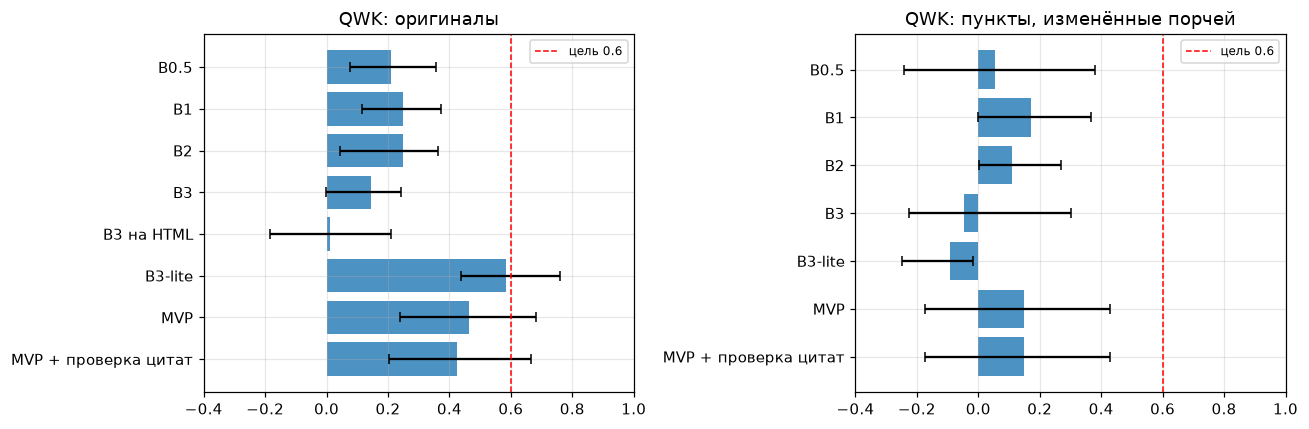

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, sl, title in [
    (axes[0], "original", "оригиналы"),
    (axes[1], "affected", "пункты, изменённые порчей"),
]:
    names = [n for n in order if n in report["methods"] and report["methods"][n][sl].get("n")]
    vals = [report["methods"][n][sl].get("qwk") or 0 for n in names]
    ci = [report["methods"][n][sl].get("qwk_ci") for n in names]
    err = np.array(
        [
            [max(v - c[0], 0), max(c[1] - v, 0)] if c else [0, 0]
            for v, c in zip(vals, ci, strict=True)
        ]
    ).T
    ax.barh(names, vals, xerr=err, color="tab:blue", alpha=0.8, capsize=3)
    ax.axvline(0.6, color="red", ls="--", lw=1, label="цель 0.6")
    ax.set_xlim(-0.4, 1)
    ax.invert_yaxis()
    ax.set_title(f"QWK: {title}")
    ax.legend(fontsize=8)
savefig("hw3_qwk")

## 3. Результат по каждому исходному БТ

In [6]:
per_source = pd.DataFrame(
    {
        n: report["methods"][n]["original"].get("qwk_by_source") or {}
        for n in ["B1", "B2", "B3", "B3-lite", "MVP"]
        if n in report["methods"]
    }
)
per_source.insert(0, "символов", prep["символов после нормализации"])
per_source.insert(1, "подбор промпта", per_source.index.isin(report["dev_sources"]))
per_source.round(2)

,символов,подбор промпта,B1,B2,B3,B3-lite,MVP
doc_01,22467,False,0.15,-0.21,0.11,0.33,0.05
doc_02,8262,True,0.29,0.33,-0.14,0.48,0.48
doc_03,4325,False,0.00,0.21,0.11,0.84,0.78
doc_04,2495,True,0.31,-0.17,0.24,0.84,0.56
doc_05,15883,False,0.38,0.30,0.07,0.50,0.58


Парное сравнение MVP с бейзлайнами: разность QWK на срезе `eval` (оригинал и изменённые пункты его копий) по первому запуску каждой конфигурации. Интервал - парный бутстреп по исходным БТ; при 5 БТ он ориентировочный, поэтому рядом показано, на скольких БТ MVP лучше. Против B3-lite MVP лучше только на 2 БТ из 5; почему основной выбрана MVP - в выводах.

In [7]:
paired = pd.DataFrame(
    {
        k: {
            **v["qwk_diff_by_source"],
            "лучше на БТ": f"{v['better_sources']} из {v['n_sources']}",
            "95% интервал": tuple(round(x, 2) for x in v["qwk_diff_ci"]),
        }
        for k, v in report["paired"].items()
    }
).T
paired

,doc_01,doc_02,doc_03,doc_04,doc_05,лучше на БТ,95% интервал
MVP - B3,0.054951,0.414866,0.514258,0.15061,0.340562,5 из 5,"(0.09, 0.43)"
MVP - B3-lite,-0.010736,-0.069027,0.135138,-0.186124,0.124956,2 из 5,"(-0.11, 0.08)"
MVP - B2,0.17118,-0.010272,0.425711,0.409589,0.336894,4 из 5,"(0.08, 0.34)"
MVP - B1,0.019687,-0.073374,0.650927,0.063309,0.110282,4 из 5,"(-0.02, 0.38)"


## 4. Ошибки основной модели

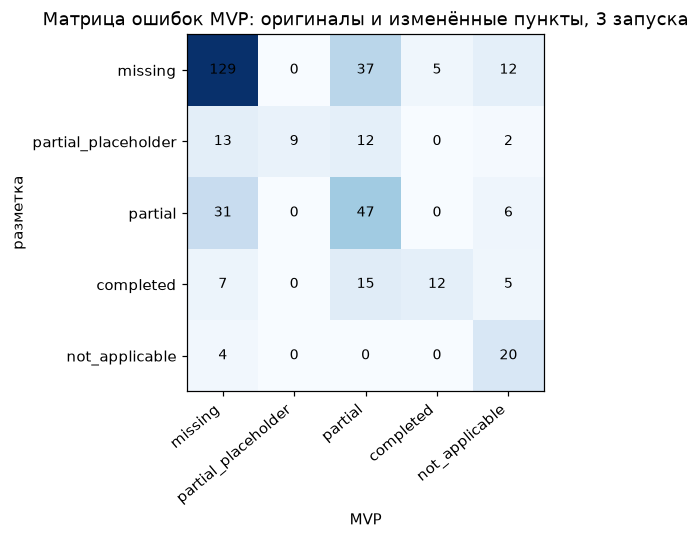

In [8]:
runs = load_llm_runs(paths, "mvp")
labels = ["missing", "partial_placeholder", "partial", "completed", "not_applicable"]
cm = pd.DataFrame(0, index=labels, columns=labels)
for run in runs.values():
    for doc_id, r in run.items():
        for item, v in r["items"].items():
            if gold[doc_id][item]["slice"] != "unaffected":
                cm.loc[gold[doc_id][item]["status"], v["status"]] += 1
cm.index.name, cm.columns.name = "разметка", "MVP"

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.imshow(cm.values, cmap="Blues")
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm.values[i, j], ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(labels)), labels, rotation=40, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("MVP")
ax.set_ylabel("разметка")
ax.grid(False)
ax.set_title("Матрица ошибок MVP: оригиналы и изменённые пункты, 3 запуска")
savefig("hw3_confusion_mvp")

Точность по пунктам чеклиста (оригиналы, среднее по запускам): пункты внизу таблицы модель проверяет ненадёжно.

In [9]:
rows = []
for run in runs.values():
    for doc_id, r in run.items():
        for item, v in r["items"].items():
            g = gold[doc_id][item]
            if g["slice"] == "original" and g["status"] != "not_applicable":
                rows.append(
                    {
                        "пункт": item,
                        "верно": v["status"] == g["status"],
                        "ложный completed": v["status"] == "completed"
                        and g["status"] != "completed",
                        "n/a на применимом": v["status"] == "not_applicable",
                    }
                )
per_item = pd.DataFrame(rows).groupby("пункт").mean().sort_values("верно", ascending=False)
per_item.round(2).T

пункт,3.3,3.5,3.4,4.1,3.8,6.2,2.2,2.3,3.6,3.10,2.6,6.4,3.9,6.1,2.4,3.7,6.3
верно,1.0,1.0,0.93,0.8,0.73,0.67,0.6,0.6,0.6,0.60,0.6,0.56,0.53,0.4,0.4,0.00,0.0
ложный completed,0.0,0.0,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.33,0.0,0.00,0.00,0.0,0.0,0.00,0.0
n/a на применимом,0.0,0.0,0.00,0.0,0.00,0.20,0.0,0.0,0.0,0.00,0.0,0.44,0.00,0.0,0.0,0.83,1.0


In [10]:
rows = []
for name, key in [("MVP", "mvp"), ("B3-lite", "lite"), ("B3", "product")]:
    for run in load_llm_runs(paths, key).values():
        for doc_id, r in run.items():
            if not r["items"]:
                continue
            op = manifest[doc_id]["operation"].replace("_2", "")
            for item, g in gold[doc_id].items():
                if g["slice"] == "affected":
                    rows.append(
                        {
                            "конфигурация": name,
                            "порча": op,
                            "верно": r["items"][item]["status"] == g["status"],
                        }
                    )
by_op = pd.DataFrame(rows).pivot_table(
    index="порча", columns="конфигурация", values="верно", aggfunc="mean"
)
by_op.round(2)

конфигурация,B3,B3-lite,MVP
порча,,,
delete_section,0.56,0.27,0.58
empty_body,0.50,0.12,0.42
placeholder,0.00,0.08,0.31


Какие статусы ставят MVP и B3-lite пунктам, изменённым порчей (сумма по 3 запускам): строки - разметка, столбцы - ответ модели.

In [11]:
rows = []
for name, key in [("MVP", "mvp"), ("B3-lite", "lite")]:
    for run in load_llm_runs(paths, key).values():
        for doc_id, r in run.items():
            for item, g in gold[doc_id].items():
                if g["slice"] == "affected":
                    rows.append(
                        {
                            "конфигурация": name,
                            "разметка": g["status"],
                            "ответ": r["items"][item]["status"],
                        }
                    )
pd.crosstab(
    [pd.DataFrame(rows)["конфигурация"], pd.DataFrame(rows)["разметка"]],
    pd.DataFrame(rows)["ответ"],
)

ответ                             missing  not_applicable  partial  \
конфигурация разметка                                                
B3-lite      missing                   16               9       44   
             partial                    0               3        3   
             partial_placeholder       13               6       17   
MVP          missing                   35               5       29   
             partial                    0               0        6   
             partial_placeholder       13               2       12   

ответ                             partial_placeholder  
конфигурация разметка                                  
B3-lite      missing                                0  
             partial                                0  
             partial_placeholder                    0  
MVP          missing                                0  
             partial                                0  
             partial_placeholder                    9

Абляция нормализации на одних и тех же документах: ответ B3 на HTML самого длинного БТ не разобрался, поэтому сравнение по 4 оригиналам из 5.

In [12]:
from reqassist.metrics import qwk

html_ok = [d for d, r in load_llm_runs(paths, "product_html")[1].items() if r["items"]]
same_docs = {}
for name, key in [("B3, нормализованный текст", "product"), ("B3 на HTML", "product_html")]:
    run = load_llm_runs(paths, key)[1]
    pairs = [
        (run[d]["items"][i]["status"], g["status"])
        for d in html_ok
        for i, g in gold[d].items()
        if g["status"] != "not_applicable"
    ]
    same_docs[name] = round(qwk([p for p, _ in pairs], [e for _, e in pairs]), 2)
pd.Series(same_docs, name=f"QWK на {', '.join(html_ok)}")

B3, нормализованный текст    0.11
B3 на HTML                   0.01
Name: QWK на doc_02, doc_03, doc_04, doc_05, dtype: float64

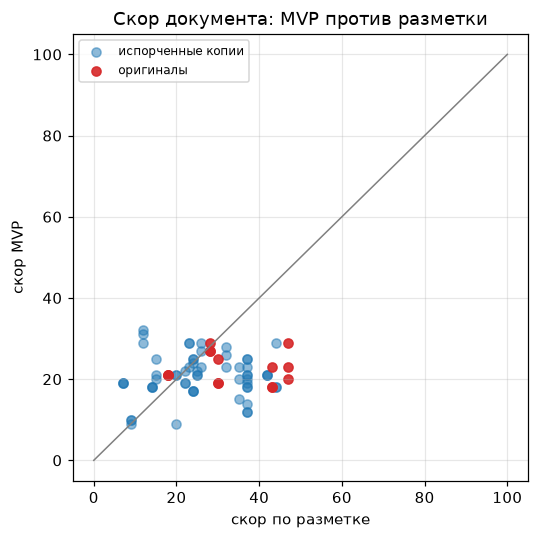

In [13]:
points = []
for doc_id, items in gold.items():
    expert = completeness_score(g["status"] for g in items.values())
    for run in runs.values():
        if run.get(doc_id, {}).get("items"):
            model = completeness_score(v["status"] for v in run[doc_id]["items"].values())
            points.append((expert, model, doc_id == manifest[doc_id]["source_id"]))
s = np.array([(e, m) for e, m, _ in points])
orig = np.array([o for *_, o in points])
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(s[~orig, 0], s[~orig, 1], alpha=0.5, label="испорченные копии")
ax.scatter(s[orig, 0], s[orig, 1], alpha=0.9, color="tab:red", label="оригиналы")
ax.plot([0, 100], [0, 100], color="gray", lw=1)
ax.set_xlabel("скор по разметке")
ax.set_ylabel("скор MVP")
ax.set_title("Скор документа: MVP против разметки")
ax.legend(fontsize=8)
savefig("hw3_score_scatter")

## 5. Стоимость, время и надёжность ответа

Время - локальная модель на ноутбуке (Apple M1 Pro, 16 ГБ), на продуктовую модель не переносится. `coverage` - документов с разобранным ответом в каждом запуске; `context_overflow` - ответов, где вход и выход вместе заняли всё окно контекста; `unlisted_items` - пункты, которых ответ продукта не упомянул ни в одном списке (считаются `missing`, как в продукте).

In [14]:
pd.DataFrame(report["llm"]).T

,calls,coverage,n_docs,parse_errors,truncated,context_overflow,seconds_mean,seconds_p95,prompt_tokens_mean,prompt_tokens_max,output_tokens_mean,conflicts,unlisted_items,unverified_quotes
MVP,75,"[25, 25, 25]",25,0,0,0,68.2,107.5,4260,7880,760,0,0,0.051546
B3-lite,75,"[25, 25, 25]",25,0,0,0,32.1,71.5,3611,7231,328,0,0,NaN
B3,25,[25],25,0,0,0,358.4,441.5,10654,14274,3284,38,144,NaN
B3 на HTML,5,[4],5,1,1,1,368.2,599.0,19816,32531,2632,7,21,NaN


## 6. История подбора промпта MVP на doc_02 и doc_04

Число пунктов из 17, где статус совпал с разметкой; v1 и v2 запускались по одному разу на части документов.

In [15]:
history = []
for version, name in [("v1", "mvp_v1_dev"), ("v2", "mvp_v2_dev")]:
    p = paths.data / f"runs/{name}.jsonl"
    if p.exists():
        for r in map(json.loads, p.read_text(encoding="utf-8").splitlines()):
            history.append(
                {
                    "версия": version,
                    "документ": r["doc_id"],
                    "совпало": sum(
                        v["status"] == gold[r["doc_id"]][i]["status"] for i, v in r["items"].items()
                    ),
                }
            )
for doc_id in ("doc_02", "doc_04"):
    for run in runs.values():
        history.append(
            {
                "версия": "v3 (итог)",
                "документ": doc_id,
                "совпало": sum(
                    v["status"] == gold[doc_id][i]["status"]
                    for i, v in run[doc_id]["items"].items()
                ),
            }
        )
pd.DataFrame(history).pivot_table(index="версия", columns="документ", values="совпало")

документ,doc_02,doc_04
версия,,
v1,NaN,10.0
v2,9.0,14.0
v3 (итог),12.0,15.0


## Выводы

Подробно, с целями 2.1 и отклонениями от плана, - раздел 2.4 дизайн-документа.

1. По QWK на eval MVP и B3-lite (0.39) выше бейзлайнов без LLM (0.13-0.26); разность MVP с B2 и B3 отделена от нуля, с B1 - нет. Промпт продукта (B3) на локальной модели слабее бейзлайнов без LLM (0.15): треть пунктов его ответ не упоминает, и они считаются `missing`.
2. Нормализация влияет на качество, не только на стоимость. На тех же 4 БТ B3 на HTML получает QWK 0.01, на нормализованном тексте 0.11; самый длинный БТ в HTML не поместился в окно 32 тыс. токенов.
3. MVP и B3-lite на eval равны: парная разность от -0.11 до +0.08. B3-lite лучше на оригиналах (0.58 против 0.46). MVP лучше на испорченных копиях: находит половину пробелов, B3-lite - четверть, и только MVP распознаёт заглушки.
4. Подбор промпта MVP на doc_02 и doc_04 его переобучил: на 3 БТ вне подбора MVP уступает B3-lite (0.44 против 0.55), на самом длинном БТ QWK 0.05.
5. Проверка цитат как фильтр не окупается: ложных `completed` у MVP и так 1.7%, а понижение статусов без подтверждённой цитаты снижает QWK с 0.46 до 0.42.
6. Цели 2.1 на локальной модели не достигнуты: QWK 0.39-0.46 при цели 0.6, macro-F1 0.51-0.59 при цели 0.7. Выполнены ложные `completed` (не больше 5%) и разбор ответов (0 ошибок из 75); MVP выше B3 на всех 5 БТ.
7. Основная модель - MVP, выбрана по recall `missing` на испорченных копиях: пропущенный пробел - главный бизнес-риск. Выбор предварительный, потому что метки копий выведены правилом. До офлайн-ворот на продуктовой модели проверяется v4: инструкции B3-lite с правилами MVP для заглушек и удалённых разделов.

Ограничения: локальная модель вместо продуктовой; 5 БТ и один разметчик без экспертной проверки; метки копий выведены правилом из цитат; 3 запуска вместо 5; интервалы бутстрепа по 5 БТ ориентировочные.